In [2]:
%pip install nbconvert
%pip install pandas
%pip install scikit-learn
%pip install --upgrade pip
%pip install kaggle pandas


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.

   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   ---------------- ----------------------- 2/5 [python-slugify]
   ---------------- ----------------------- 2/5 [python-slugify]
   ------------------------ --------------- 3/5 [protobuf]
   ------------------------ --------------- 3/5 [protobuf]
   ------------------------ --------------- 3/5 [protobuf]
   ------------------------ --------------- 3/5 [protobuf]
   ------------------------ --------------- 3/5 [protobuf]
   ------------------------ --------------- 3

In [3]:
%pip install kagglehub pandas


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ------------------------------------

In [5]:
%pip install --upgrade jupyter ipywidgets


   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.2 MB 6.7 MB/s eta 0:00:01
   ---------------------------- ----------- 1.6/2.2 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 5.5 MB/s  0:00:00

   -------- ------------------------------- 1/5 [jupyterlab_widgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- ----------------------- 2/5 [ipywidgets]
   ---------------- -----

In [2]:
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# Загрузка датасета
file_path = r"C:\Users\user\.cache\kagglehub\datasets\gustavomodelli\forest-fires-in-brazil\versions\1\amazon.csv"

data = pd.read_csv(file_path, encoding="latin1")

# Выводим первые строки
display(data.head())

print("Размер датасета:", data.shape)
print("Названия столбцов:", data.columns.tolist())

,year,state,month,number,date
0,1998,Acre,Janeiro,0.0,1998-01-01
1,1999,Acre,Janeiro,0.0,1999-01-01
2,2000,Acre,Janeiro,0.0,2000-01-01
3,2001,Acre,Janeiro,0.0,2001-01-01
4,2002,Acre,Janeiro,0.0,2002-01-01


Размер датасета: (6454, 5)
Названия столбцов: ['year', 'state', 'month', 'number', 'date']


In [3]:
# Выбираем признаки, необходимые для анализа
data_sel = data[
    ['year', 'state', 'month', 'number', 'date']
].copy()

# Проверяем пропущенные значения
print("Пропуски до обработки:")
print(data_sel.isnull().sum())

# Удаляем строки с пропущенными значениями
data_sel = data_sel.dropna().copy()

# Проверяем результат
print("\nРазмер данных после обработки:", data_sel.shape)
print("\nКоличество дубликатов:", data_sel.duplicated().sum())

display(data_sel.head())

Пропуски до обработки:
year      0
state     0
month     0
number    0
date      0
dtype: int64

Размер данных после обработки: (6454, 5)

Количество дубликатов: 32


,year,state,month,number,date
0,1998,Acre,Janeiro,0.0,1998-01-01
1,1999,Acre,Janeiro,0.0,1999-01-01
2,2000,Acre,Janeiro,0.0,2000-01-01
3,2001,Acre,Janeiro,0.0,2001-01-01
4,2002,Acre,Janeiro,0.0,2002-01-01


In [4]:
# Выделяем целевой признак
threshold = data_sel['number'].median()

data_sel['fire_level'] = np.where(
    data_sel['number'] > threshold, 1, 0
)

# Целевая переменная
Fire = data_sel[['fire_level']]

# Признаки для анализа
X = data_sel[
    ['year', 'state', 'month']
]

# Проверяем результат
print("Медиана количества пожаров:", threshold)

print("\nРаспределение целевого признака:")
print(Fire['fire_level'].value_counts())

print("\nВходные признаки X:")
display(X.head())

print("\nЦелевой признак Fire:")
display(Fire.head())

Медиана количества пожаров: 24.0

Распределение целевого признака:
fire_level
0    3241
1    3213
Name: count, dtype: int64

Входные признаки X:


,year,state,month
0,1998,Acre,Janeiro
1,1999,Acre,Janeiro
2,2000,Acre,Janeiro
3,2001,Acre,Janeiro
4,2002,Acre,Janeiro



Целевой признак Fire:


,fire_level
0,0
1,0
2,0
3,0
4,0


In [5]:
from sklearn.model_selection import train_test_split

# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Fire['fire_level'],
    test_size=0.33,
    random_state=42,
    stratify=Fire['fire_level']
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nОбучающая выборка:")
display(X_train.head())

print("\nТестовая выборка:")
display(X_test.head())

Размер обучающей выборки: (4324, 3)
Размер тестовой выборки: (2130, 3)

Обучающая выборка:


,year,state,month
5868,2009,Sao Paulo,Julho
2828,2016,Mato Grosso,Outubro
1773,2017,Espirito Santo,Maio
116,2014,Acre,Junho
3838,2011,Pernambuco,Janeiro



Тестовая выборка:


,year,state,month
1892,2016,Espirito Santo,Novembro
2663,2011,Mato Grosso,Fevereiro
353,2011,Alagoas,Junho
1179,2000,Bahia,Dezembro
4345,2000,Rio,Março


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Категориальные и числовые признаки
categorical_features = ['state', 'month']
numeric_features = ['year']

# Преобразование признаков
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numeric_features)
    ]
)

# Обучаем преобразование только на обучающей выборке
X_train_prepared = preprocessor.fit_transform(X_train)

# Применяем те же преобразования к тестовой выборке
X_test_prepared = preprocessor.transform(X_test)

print("Размер обучающей матрицы:", X_train_prepared.shape)
print("Размер тестовой матрицы:", X_test_prepared.shape)

Размер обучающей матрицы: (4324, 36)
Размер тестовой матрицы: (2130, 36)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Создаём и обучаем модель
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_prepared, y_train)

# Предсказания на тестовой выборке
y_pred_lr = lr.predict(X_test_prepared)

# Оценка качества модели
print("Логистическая регрессия")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_lr, zero_division=0))

Логистическая регрессия
Accuracy: 0.6708920187793427
Precision: 0.6707897240723121
Recall: 0.6650943396226415
F1-score: 0.6679298910468972


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train_prepared, y_train)

y_pred_rf = rf.predict(X_test_prepared)

print("Случайный лес")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_rf, zero_division=0))

Случайный лес
Accuracy: 0.7605633802816901
Precision: 0.7495462794918331
Recall: 0.779245283018868
F1-score: 0.7641073080481036


In [9]:
results = pd.DataFrame({
    'Модель': ['Логистическая регрессия', 'Случайный лес'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ]
})

display(results.round(4))

,Модель,Accuracy,Precision,Recall,F1-score
0,Логистическая регрессия,0.6709,0.6708,0.6651,0.6679
1,Случайный лес,0.7606,0.7495,0.7792,0.7641


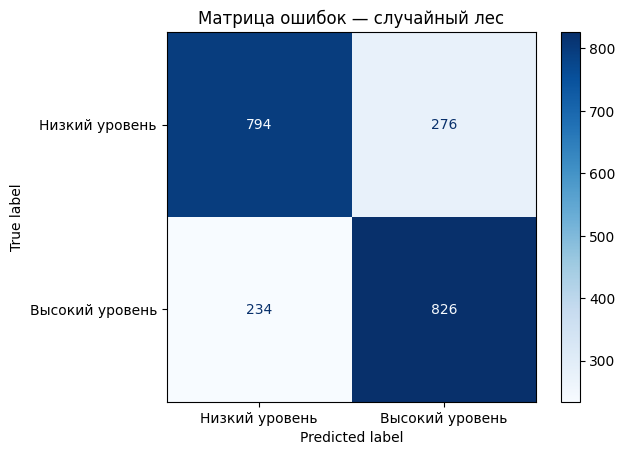

Отчёт о классификации:
                 precision    recall  f1-score   support

 Низкий уровень       0.77      0.74      0.76      1070
Высокий уровень       0.75      0.78      0.76      1060

       accuracy                           0.76      2130
      macro avg       0.76      0.76      0.76      2130
   weighted avg       0.76      0.76      0.76      2130



In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=['Низкий уровень', 'Высокий уровень'],
    cmap='Blues'
)

plt.title('Матрица ошибок — случайный лес')
plt.show()

print("Отчёт о классификации:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Низкий уровень', 'Высокий уровень'],
    zero_division=0
))

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_prepared, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший F1-score на кросс-валидации:")
print(round(grid_search.best_score_, 4))

Лучшие параметры:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}

Лучший F1-score на кросс-валидации:
0.777


In [14]:
# Получаем модель с лучшими параметрами
best_rf = grid_search.best_estimator_

# Делаем предсказания на тестовой выборке
y_pred_best = best_rf.predict(X_test_prepared)

# Оцениваем качество модели
print("Случайный лес после настройки параметров")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_best, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_best, zero_division=0))

Случайный лес после настройки параметров
Accuracy: 0.77981220657277
Precision: 0.7703568161024703
Recall: 0.7943396226415095
F1-score: 0.782164421737111


In [15]:
final_results = pd.DataFrame({
    'Модель': [
        'Логистическая регрессия',
        'Случайный лес',
        'Случайный лес после настройки'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_best)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_best, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_best, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_best, zero_division=0)
    ]
})

display(final_results.round(4))

,Модель,Accuracy,Precision,Recall,F1-score
0,Логистическая регрессия,0.6709,0.6708,0.6651,0.6679
1,Случайный лес,0.7606,0.7495,0.7792,0.7641
2,Случайный лес после настройки,0.7798,0.7704,0.7943,0.7822


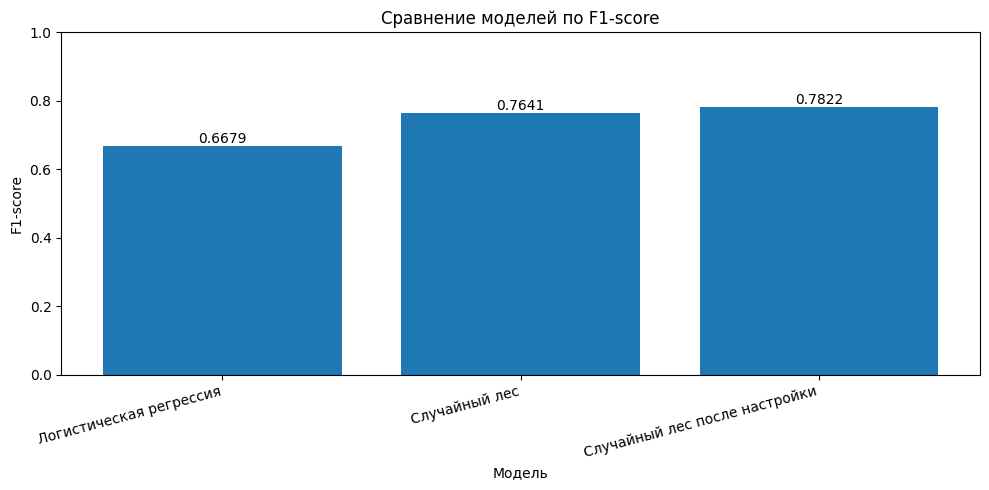

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    final_results['Модель'],
    final_results['F1-score']
)

plt.title('Сравнение моделей по F1-score')
plt.xlabel('Модель')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.xticks(rotation=15, ha='right')

for i, value in enumerate(final_results['F1-score']):
    plt.text(i, value + 0.01, f'{value:.4f}', ha='center')

plt.tight_layout()
plt.show()

,Признак,Важность
35,num__year,0.2601
34,cat__month_Setembro,0.0490
33,cat__month_Outubro,0.0400
20,cat__state_Sao Paulo,0.0317
24,cat__month_Agosto,0.0314
9,cat__state_Maranhao,0.0262
6,cat__state_Distrito Federal,0.0247
28,cat__month_Julho,0.0247
16,cat__state_Rio,0.0241
31,cat__month_Março,0.0233


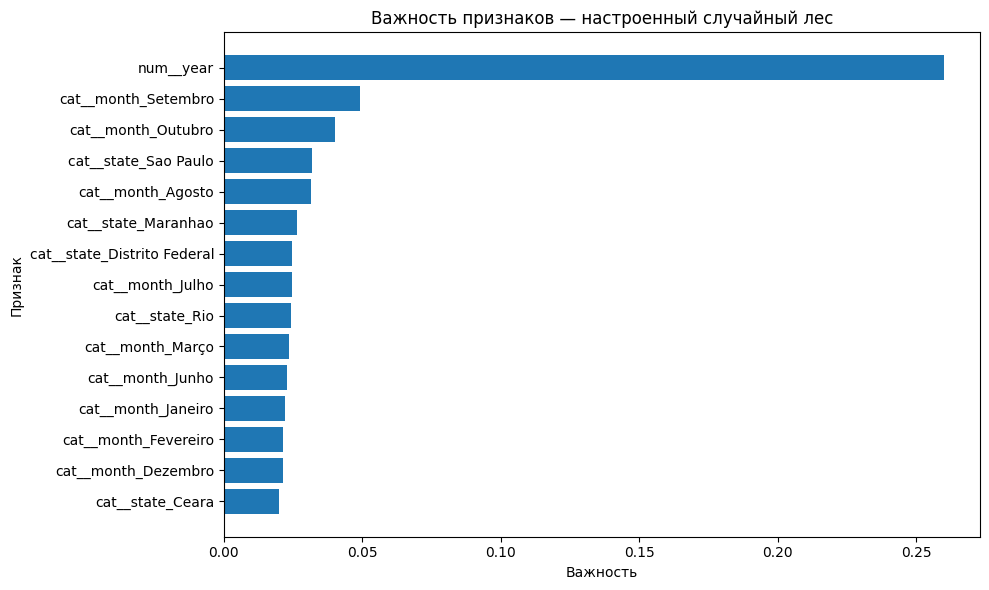

In [17]:
# Получаем названия признаков после предобработки
feature_names = preprocessor.get_feature_names_out()

# Важность признаков настроенного случайного леса
importances = best_rf.feature_importances_

importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': importances
}).sort_values('Важность', ascending=False)

display(importance_df.head(15).round(4))

# Строим график для 15 наиболее важных признаков
top_features = importance_df.head(15).sort_values('Важность')

plt.figure(figsize=(10, 6))
plt.barh(top_features['Признак'], top_features['Важность'])
plt.title('Важность признаков — настроенный случайный лес')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

,Признак,Важность
35,num__year,0.2601
34,cat__month_Setembro,0.0490
33,cat__month_Outubro,0.0400
20,cat__state_Sao Paulo,0.0317
24,cat__month_Agosto,0.0314
9,cat__state_Maranhao,0.0262
6,cat__state_Distrito Federal,0.0247
28,cat__month_Julho,0.0247
16,cat__state_Rio,0.0241
31,cat__month_Março,0.0233


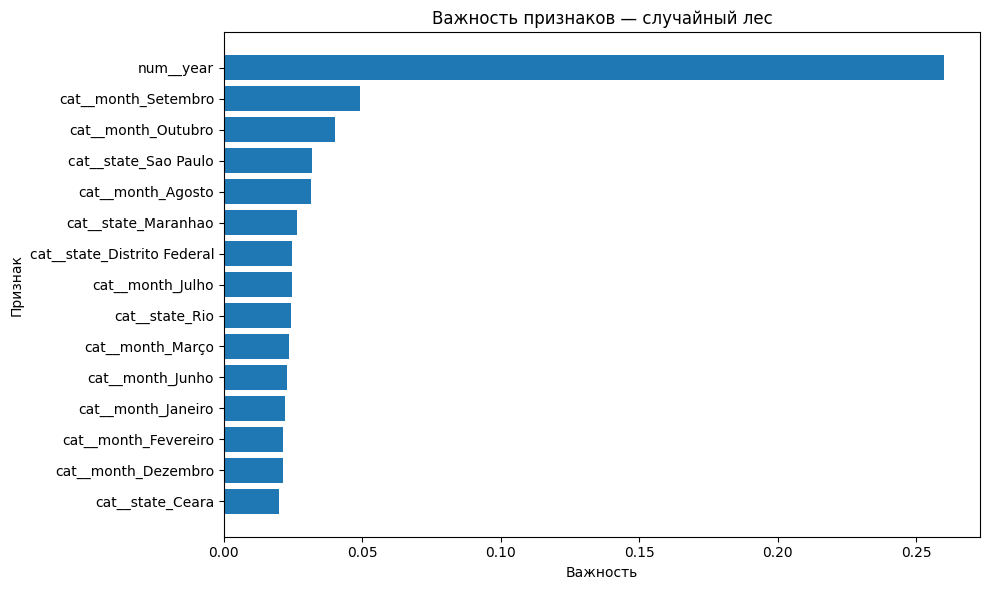

In [18]:
# Важность признаков настроенного случайного леса
feature_names = preprocessor.get_feature_names_out()
importances = best_rf.feature_importances_

importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': importances
}).sort_values('Важность', ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values('Важность')

plt.figure(figsize=(10, 6))
plt.barh(top_features['Признак'], top_features['Важность'])
plt.title('Важность признаков — случайный лес')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()